# XGBoost Lab — see every claim from the README with your own eyes

This notebook is the hands-on companion to [`../README.md`](../README.md).
Every lab is **self-contained**: a short goal, the code, the numbers/picture, and a
**"How to read this"** box that tells you what you should notice.

**How to use it**

1. Run the first code cell (imports) and the helper cell. After that you can run the labs in order (`Shift + Enter`
   cell by cell) or `Run All`. Labs only reuse data from *earlier* cells, so top-to-bottom always works.
2. Look at the output and **guess** what it means before you read the "How to read this" box.
3. Change the numbers marked `# <- try changing this` and re-run to build intuition.

| Part | Labs | What it shows |
|---|---|---|
| **A. How XGBoost works** | 1 – 8 | The hand-worked example; gradients, hessians and gains; λ, γ, α; the logistic loss; Newton leaves vs classic gradient boosting; learning rate; early stopping; exact vs approx vs hist |
| **B. Why it is useful** | 9 – 11 | Built-in missing-value handling (vs imputation), row/column subsampling, monotone constraints |
| **C. Where it fails** | 12 – 16 | p ≫ n with a linear signal, extrapolation, tiny noisy data and over-tuning, high-cardinality categories, the tuning burden |

All data is generated inside this notebook (and saved to `data/`) — **no internet needed**.

In [1]:
import json
import pathlib
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse
import xgboost as xgb

from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score, log_loss, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
print("xgboost", xgb.__version__)

xgboost 3.4.1


Three tiny helpers used by several labs. `tree_json` turns xgboost's text dump of one tree into a Python dict
(pandas is not needed); the other two walk that dict.

In [2]:
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def tree_json(model, i=0):
    """Tree number i of a fitted xgboost model, as a nested dict (keys: split, split_condition, gain, leaf, ...)."""
    return json.loads(model.get_booster().get_dump(dump_format="json", with_stats=True)[i])


def leaves_of(node):
    """All leaf values of one tree dict, left to right."""
    if "leaf" in node:
        return [node["leaf"]]
    return [v for child in node["children"] for v in leaves_of(child)]

---
# The two datasets

* **good fit** — 8 000 rows, 8 numeric features, a non-linear target with interactions, and **informative missing
  values**: four columns are blank in about a third of the rows, blanks happen more often when the true value is
  large, and *whether a value is blank* changes the target (together with the sign of `x8`). Think of a hospital
  table where a lab test is skipped more often for some patients, and the skip itself tells you something.
  Gradient-boosted trees with built-in missing-value handling are made for this.
* **bad fit** — 150 rows, **400** features, and a target that is a *straight-line* (linear) combination of just
  10 of them plus noise. Trees approximate a straight line with many little steps and need lots of data to do it;
  a regularised linear model is exactly the right shape.

Both generators save a CSV in `data/` (rounded to 4 significant digits) and the labs then **load the CSV**, so the
from-scratch notebook uses exactly the same numbers.

good_fit.csv: 482 KB
bad_fit.csv: 432 KB
good fit: (8000, 8)  share missing per column: [0.   0.34 0.33 0.   0.34 0.   0.34 0.  ]
bad fit : (150, 400)  non-zero true coefficients: 10


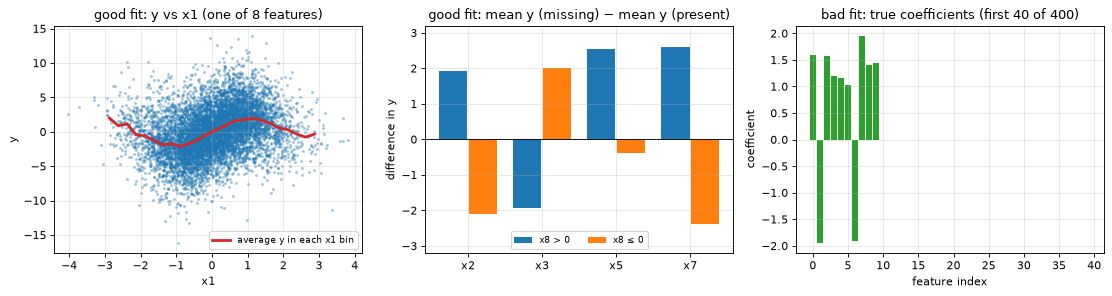

In [3]:
DATA = pathlib.Path("data")
DATA.mkdir(exist_ok=True)


def make_good_fit(seed=0, n=8000, save=True):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, 8))
    y = (2 * np.sin(1.5 * X[:, 0]) + 1.5 * X[:, 1] * X[:, 2] + 2.0 * (X[:, 3] > 0) * X[:, 4]
         + 0.5 * X[:, 5] + rng.normal(scale=0.5, size=n))
    for j, shift in [(1, 2.0), (2, -2.0), (4, 1.5), (6, 2.5)]:          # columns x2, x3, x5, x7 get blanks
        missing = rng.random(n) < 1 / (1 + np.exp(-(1.5 * X[:, j] - 1.0)))  # large values go missing more often
        y = y + shift * missing * np.sign(X[:, 7])                          # ...and "missing" carries signal
        X[missing, j] = np.nan
    if save:
        np.savetxt(DATA / "good_fit.csv", np.column_stack([X, y]), delimiter=",",
                   header=",".join([f"x{j + 1}" for j in range(8)] + ["y"]), comments="", fmt="%.4g")
    return X, y


def make_bad_fit(seed=0, n=150, p=400):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, p))
    beta = np.zeros(p)
    beta[:10] = rng.choice([-1, 1], 10) * rng.uniform(1, 2, 10)   # only the first 10 features matter
    y = X @ beta + rng.normal(scale=1.0, size=n)
    np.savetxt(DATA / "bad_fit.csv", np.column_stack([X, y]), delimiter=",",
               header=",".join([f"x{j + 1}" for j in range(p)] + ["y"]), comments="", fmt="%.4g")
    return X, y, beta


make_good_fit(0)
_, _, beta_bad = make_bad_fit(0)
good = np.loadtxt(DATA / "good_fit.csv", delimiter=",", skiprows=1)
bad = np.loadtxt(DATA / "bad_fit.csv", delimiter=",", skiprows=1)
X_good, y_good = good[:, :-1], good[:, -1]
X_bad, y_bad = bad[:, :-1], bad[:, -1]
for name in ["good_fit.csv", "bad_fit.csv"]:
    print(f"{name}: {(DATA / name).stat().st_size / 1e3:.0f} KB")
print("good fit:", X_good.shape, " share missing per column:", np.isnan(X_good).mean(axis=0).round(2))
print("bad fit :", X_bad.shape, " non-zero true coefficients:", np.count_nonzero(beta_bad))

# one split for the whole notebook: train (6000) / test (2000); validation is cut from train when needed
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(X_good, y_good, test_size=0.25, random_state=0)
Xg_fit, Xg_val, yg_fit, yg_val = train_test_split(Xg_tr, yg_tr, test_size=0.25, random_state=0)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X_bad, y_bad, test_size=0.3, random_state=0)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].scatter(X_good[:, 0], y_good, s=3, alpha=0.3)
edges_x1 = np.linspace(-3, 3, 25)
mid_x1 = (edges_x1[1:] + edges_x1[:-1]) / 2
bin_mean = [y_good[(X_good[:, 0] >= lo) & (X_good[:, 0] < hi)].mean() for lo, hi in zip(edges_x1[:-1], edges_x1[1:])]
axes[0].plot(mid_x1, bin_mean, color="tab:red", lw=2.5, label="average y in each x1 bin")
axes[0].set(title="good fit: y vs x1 (one of 8 features)", xlabel="x1", ylabel="y"); axes[0].legend(loc="lower right", fontsize=8)
x8_pos = X_good[:, 7] > 0
for k, (j, name) in enumerate([(1, "x2"), (2, "x3"), (4, "x5"), (6, "x7")]):
    miss = np.isnan(X_good[:, j])
    for side, sel, c in [(-0.2, x8_pos, "tab:blue"), (0.2, ~x8_pos, "tab:orange")]:
        diff = y_good[miss & sel].mean() - y_good[~miss & sel].mean()
        axes[1].bar(k + side, diff, width=0.38, color=c, label=("x8 > 0" if sel is x8_pos else "x8 ≤ 0") if k == 0 else None)
axes[1].set_xticks(range(4), ["x2", "x3", "x5", "x7"]); axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(title="good fit: mean y (missing) − mean y (present)", ylabel="difference in y", ylim=(-3.2, 3.2))
axes[1].legend(loc="lower center", ncol=2, fontsize=8)
axes[2].bar(np.arange(40), beta_bad[:40], color="tab:green")
axes[2].set(title="bad fit: true coefficients (first 40 of 400)", xlabel="feature index", ylabel="coefficient")
plt.tight_layout(); plt.show()

> **How to read this**
> * Left: the cloud is wide (other features and noise), but the red line of bin averages shows that the target
>   depends on `x1` through a wave — a non-linear shape a straight line cannot follow. The other
>   features add an interaction (`x2·x3`), a switch (`x5` only matters when `x4 > 0`) and noise.
> * Middle: rows where a value is **missing** have a clearly different target from rows where it is present — up or
>   down depending on the sign of `x8`. So "missing" is information, not just a hole to be filled.
> * Right: in the bad-fit data only 10 of the 400 coefficients are non-zero. With 150 rows and 400 columns
>   ("p ≫ n"), a model must find those 10 needles in a haystack.

---
# Part A — How XGBoost works

## Lab 1 · The hand-worked example, done by the computer

**Goal:** reproduce README §5 number by number: six points, squared error, λ = 1, γ = 0, learning rate η = 0.3,
`max_depth = 2`. We compute g, h, the similarity score of every node, the gain of every candidate split, the leaf
weights w* and the new predictions — first by hand in NumPy, then with `xgboost` itself.

In [4]:
x_toy = np.array([1, 2, 3, 4, 5, 6], dtype=float)
y_toy = np.array([1, 3, 2, 7, 8, 15], dtype=float)
lam, gamma, eta = 1.0, 0.0, 0.3                 # <- try changing this (λ = 0 lets the left node split too)

base = y_toy.mean()                              # starting prediction for everyone (= 6)
g_toy = base - y_toy                             # gradient of ½(y − ŷ)² w.r.t. ŷ:  g = ŷ − y
h_toy = np.ones_like(g_toy)                      # hessian: h = 1
print("base prediction:", base)
print(" x   y   residual   g    h")
for xi, yi, gi, hi in zip(x_toy, y_toy, g_toy, h_toy):
    print(f"{xi:2.0f} {yi:4.0f} {yi - base:8.0f} {gi:6.0f} {hi:4.0f}")


def similarity(G, H, lam):
    return G ** 2 / (H + lam)


def gain_table(rows, lam, title):
    """Print the gain of every threshold between neighbouring x values of the rows in one node."""
    xs, gs, hs = x_toy[rows], g_toy[rows], h_toy[rows]
    ss_parent = similarity(gs.sum(), hs.sum(), lam)
    print(f"\n{title}: G = {gs.sum():.0f}, H = {hs.sum():.0f}, similarity = {ss_parent:.3f}")
    print(" split     G_L  H_L   SS_L     G_R  H_R   SS_R    gain = ½(SS_L+SS_R−SS)")
    for t in (xs[1:] + xs[:-1]) / 2:
        L = xs < t
        ssl, ssr = similarity(gs[L].sum(), hs[L].sum(), lam), similarity(gs[~L].sum(), hs[~L].sum(), lam)
        print(f" x<{t:.1f}  {gs[L].sum():5.0f} {hs[L].sum():4.0f} {ssl:6.3f}  {gs[~L].sum():5.0f} {hs[~L].sum():4.0f} {ssr:6.3f}"
              f"   {0.5 * (ssl + ssr - ss_parent) - gamma:7.3f}")


gain_table(np.arange(6), lam, "root (all 6 points)")
gain_table(np.arange(3), lam, "left child x<3.5 (points 1-3)")
gain_table(np.arange(3, 6), lam, "right child x≥3.5 (points 4-6)")

leaves = {"x<3.5": [0, 1, 2], "3.5≤x<5.5": [3, 4], "x≥5.5": [5]}
pred_toy = np.full(6, base)
print("\nleaf          G     H     w* = −G/(H+λ)   η·w*")
for name, rows in leaves.items():
    G, H = g_toy[rows].sum(), h_toy[rows].sum()
    w = -G / (H + lam)
    pred_toy[rows] += eta * w
    print(f"{name:11s} {G:5.0f} {H:5.0f} {w:12.3f} {eta * w:10.3f}")
print("new predictions:", pred_toy)

base prediction: 6.0
 x   y   residual   g    h
 1    1       -5      5    1
 2    3       -3      3    1
 3    2       -4      4    1
 4    7        1     -1    1
 5    8        2     -2    1
 6   15        9     -9    1

root (all 6 points): G = 0, H = 6, similarity = 0.000
 split     G_L  H_L   SS_L     G_R  H_R   SS_R    gain = ½(SS_L+SS_R−SS)
 x<1.5      5    1 12.500     -5    5  4.167     8.333
 x<2.5      8    2 21.333     -8    4 12.800    17.067
 x<3.5     12    3 36.000    -12    3 36.000    36.000
 x<4.5     11    4 24.200    -11    2 40.333    32.267
 x<5.5      9    5 13.500     -9    1 40.500    27.000

left child x<3.5 (points 1-3): G = 12, H = 3, similarity = 36.000
 split     G_L  H_L   SS_L     G_R  H_R   SS_R    gain = ½(SS_L+SS_R−SS)
 x<1.5      5    1 12.500      7    2 16.333    -3.583
 x<2.5      8    2 21.333      4    1  8.000    -3.333

right child x≥3.5 (points 4-6): G = -12, H = 3, similarity = 36.000
 split     G_L  H_L   SS_L     G_R  H_R   SS_R    gain =

In [5]:
model_toy = xgb.XGBRegressor(n_estimators=1, max_depth=2, learning_rate=eta, reg_lambda=lam, gamma=gamma,
                             min_child_weight=1, tree_method="exact", base_score=base)
model_toy.fit(x_toy.reshape(-1, 1), y_toy)
print("xgboost predictions:", model_toy.predict(x_toy.reshape(-1, 1)))
print(json.dumps(tree_json(model_toy), indent=1))

# what base_score does xgboost pick by itself? (xgboost >= 2 estimates it from the data)
auto = xgb.XGBRegressor(n_estimators=1, tree_method="exact").fit(x_toy.reshape(-1, 1), y_toy)
cfg = json.loads(auto.get_booster().save_config())
print("base_score estimated by xgboost when not given:", cfg["learner"]["learner_model_param"]["base_score"])

xgboost predictions: [5.1  5.1  5.1  6.3  6.3  7.35]
{
 "nodeid": 0,
 "depth": 0,
 "split": "f0",
 "split_condition": 3.5,
 "yes": 1,
 "no": 2,
 "missing": 1,
 "gain": 72,
 "cover": 6,
 "children": [
  {
   "nodeid": 1,
   "leaf": -0.900000036,
   "cover": 3
  },
  {
   "nodeid": 2,
   "depth": 1,
   "split": "f0",
   "split_condition": 5.5,
   "yes": 3,
   "no": 4,
   "missing": 3,
   "gain": 7.5,
   "cover": 3,
   "children": [
    {
     "nodeid": 3,
     "leaf": 0.300000012,
     "cover": 2
    },
    {
     "nodeid": 4,
     "leaf": 1.35000002,
     "cover": 1
    }
   ]
  }
 ]
}
base_score estimated by xgboost when not given: [6E0]


> **How to read this**
> * The NumPy table gives exactly the README numbers: at the root the best split is `x < 3.5` with gain **36**
>   (others: 8.333, 17.067, 32.267, 27). In the left child every gain is negative (−3.583, −3.333), so it stays a
>   leaf; in the right child `x < 5.5` wins with gain **3.75**.
> * Leaf weights are −3, 1 and 4.5; times η = 0.3 that is −0.9, 0.3 and 1.35, and the predictions move from 6 to
>   **5.1, 5.1, 5.1, 6.3, 6.3, 7.35** — the same numbers xgboost prints.
> * xgboost's tree dump has the same thresholds (`split_condition` 3.5 and 5.5; "yes" = `x < split_condition`)
>   and the same leaf values (−0.900000036 is −0.9 stored as a 32-bit float).
> * **Watch the units of "gain".** xgboost reports `gain: 72` and `gain: 7.5` — exactly **twice** our 36 and 3.75,
>   because the library leaves out the ½. It also compares γ with this doubled number (Lab 3 shows it).
> * With no `base_score` given, xgboost 3.4.1 estimated it as **6** — the mean of y (the best constant for
>   squared error). In comparisons we always set it explicitly so nothing depends on that estimate.

## Lab 2 · The histogram example from the old notes, finished

**Goal:** complete the histogram (binned) split example (README §4.8): 5 samples with given g and h, 3 bins,
G and H per bin, and the gain of **both** candidate splits for λ = 1, γ = 0. Then compare with the exact method,
which may cut between any two neighbouring values.

In [6]:
feat = np.array([2.1, 2.5, 3.2, 3.7, 4.0])
g_h = np.array([-0.8, -0.6, 0.2, 0.4, 0.5])        # gradients (pretend some loss produced them)
h_h = np.array([1.2, 1.1, 0.9, 1.0, 1.3])          # hessians
edges = np.array([2.0, 2.7, 3.5, 4.2])             # bins (2.0, 2.7], (2.7, 3.5], (3.5, 4.2]
bin_of = np.digitize(feat, edges[1:-1], right=True)
G_bin = np.bincount(bin_of, weights=g_h, minlength=3)
H_bin = np.bincount(bin_of, weights=h_h, minlength=3)
print("bin of each sample:", bin_of + 1)
print("G per bin:", G_bin, "  H per bin:", H_bin)


def split_gain(GL, HL, GR, HR, lam=1.0, gamma=0.0):
    return 0.5 * (similarity(GL, HL, lam) + similarity(GR, HR, lam) - similarity(GL + GR, HL + HR, lam)) - gamma


for k in [1, 2]:
    GL, HL, GR, HR = G_bin[:k].sum(), H_bin[:k].sum(), G_bin[k:].sum(), H_bin[k:].sum()
    print(f"split after bin {k}: G_L={GL:.1f} H_L={HL:.1f} | G_R={GR:.1f} H_R={HR:.1f}  -> gain = {split_gain(GL, HL, GR, HR):.3f}")

print("\nexact method: every gap between neighbouring values is a candidate")
for t in (feat[1:] + feat[:-1]) / 2:
    L = feat < t
    print(f"  x < {t:.2f}: gain = {split_gain(g_h[L].sum(), h_h[L].sum(), g_h[~L].sum(), h_h[~L].sum()):.3f}")

bin of each sample: [1 1 2 3 3]
G per bin: [-1.4  0.2  0.9]   H per bin: [2.3 0.9 2.3]
split after bin 1: G_L=-1.4 H_L=2.3 | G_R=1.1 H_R=3.2  -> gain = 0.434
split after bin 2: G_L=-1.2 H_L=3.2 | G_R=0.9 H_R=2.3  -> gain = 0.287

exact method: every gap between neighbouring values is a candidate
  x < 2.30: gain = 0.162
  x < 2.85: gain = 0.434
  x < 3.45: gain = 0.287
  x < 3.85: gain = 0.109


On a realistic column (2 000 values) the exact method tries ~2 000 thresholds; the histogram method only tries the
borders of a few bins placed at **quantiles** (equal-count bins), so most of the gain curve is never looked at.
How much is lost?

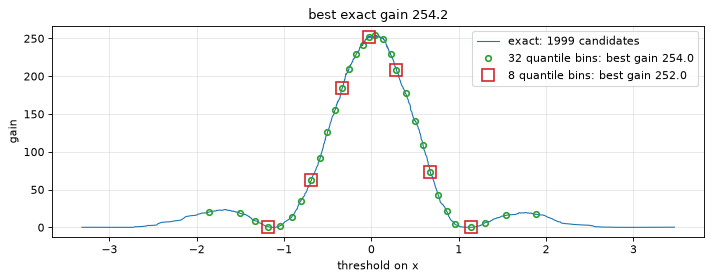

In [7]:
rng = np.random.default_rng(1)
x_c = rng.normal(size=2000)
y_c = np.sin(2 * x_c) + rng.normal(scale=0.3, size=2000)
g_c, h_c = -(y_c - y_c.mean()), np.ones(2000)               # squared error around the mean
order = np.argsort(x_c)
xs, GL, HL = x_c[order], np.cumsum(g_c[order]), np.cumsum(h_c[order])
G, H = GL[-1], HL[-1]
exact_gain = 0.5 * (GL[:-1] ** 2 / (HL[:-1] + 1) + (G - GL[:-1]) ** 2 / (H - HL[:-1] + 1) - G ** 2 / (H + 1))
thresholds = (xs[1:] + xs[:-1]) / 2

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(thresholds, exact_gain, lw=1, label=f"exact: {len(thresholds)} candidates")
for n_bins, c, mk, ms in [(32, "tab:green", "o", 5), (8, "tab:red", "s", 10)]:   # <- try changing this
    cuts = np.quantile(x_c, np.linspace(0, 1, n_bins + 1)[1:-1])
    idx = np.searchsorted(thresholds, cuts).clip(0, len(thresholds) - 1)
    ax.plot(thresholds[idx], exact_gain[idx], mk, color=c, ms=ms, mfc="none", mew=1.5,
            label=f"{n_bins} quantile bins: best gain {exact_gain[idx].max():.1f}")
ax.set(xlabel="threshold on x", ylabel="gain", title=f"best exact gain {exact_gain.max():.1f}")
ax.legend(); plt.tight_layout(); plt.show()

> **How to read this**
> * Bins: samples 1–2 → bin 1, sample 3 → bin 2, samples 4–5 → bin 3. G per bin = (−1.4, 0.2, 0.9),
>   H per bin = (2.3, 0.9, 2.3) — the table from the old notes.
> * Split after bin 1: ½[1.96/3.3 + 1.21/4.2 − 0.09/6.5] = **0.434**. Split after bin 2: ½[1.44/4.2 + 0.81/3.3 −
>   0.09/6.5] = **0.287**. So the split after bin 1 (between 2.5 and 3.2) wins. (xgboost would print 0.868 —
>   twice — see Lab 1.)
> * The exact method also tries `x < 2.30` and `x < 3.85`; neither beats 0.434 here, so binning lost nothing.
> * The curve: the exact method evaluates every point on the blue line; 32 quantile bins land close to its peak,
>   8 bins a bit lower. The price of binning is a slightly worse threshold; the reward is speed (Lab 8).

## Lab 3 · λ, γ and α: how the regularisation knobs change a tree

**Goal:** check README §4.4–4.6 on a single tree: λ shrinks **every** leaf weight towards 0 (w* = −G/(H+λ)) and
lowers every gain; γ removes splits whose gain is too small (xgboost compares γ with its doubled "gain");
α (L1) sets leaves with small |G| **exactly** to 0.

 λ      leaves  largest |leaf|   check: −G/(H+λ) of the leaf holding x[0]
   0       15        2.822              0.228  (xgboost: 0.228)
   1       15        2.770              0.190  (xgboost: 0.190)
  10       11        2.198              0.076  (xgboost: 0.076)
 100        9        1.038             -0.001  (xgboost: -0.001)


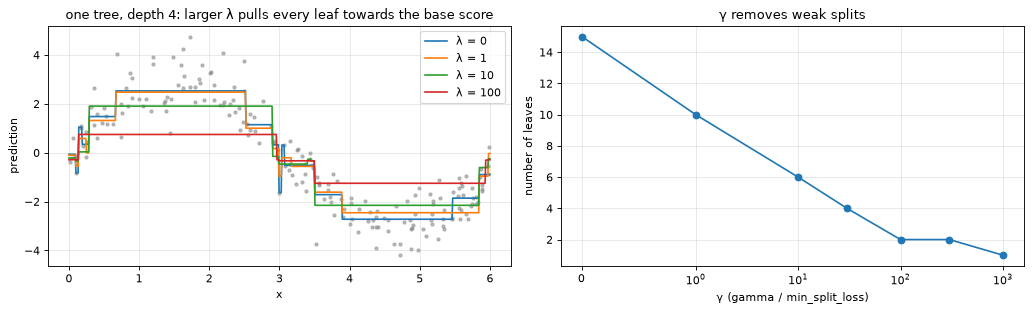

leaves for γ = {0: 15, 1: 10, 10: 6, 30: 4, 100: 2, 300: 2, 1000: 1}
xgboost 'gain' of each split in the γ = 0 tree: [  0.2   0.3   0.4   0.5   0.8   1.1   1.3   4.2   5.6  15.1  17.8  37.6
  45.2 710.9]


In [8]:
rng = np.random.default_rng(0)
x_s = np.sort(rng.uniform(0, 6, 200)).reshape(-1, 1)
y_s = np.sin(x_s[:, 0]) * 3 + rng.normal(scale=0.7, size=200)
one_tree = dict(n_estimators=1, max_depth=4, learning_rate=1.0, tree_method="exact", base_score=float(y_s.mean()))

grid = np.linspace(0, 6, 600).reshape(-1, 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(x_s, y_s, s=8, color="gray", alpha=0.5)
print(" λ      leaves  largest |leaf|   check: −G/(H+λ) of the leaf holding x[0]")
for lam_k in [0, 1, 10, 100]:                                    # <- try changing this
    m = xgb.XGBRegressor(**one_tree, reg_lambda=lam_k).fit(x_s, y_s)
    vals = leaves_of(tree_json(m))
    leaf0 = m.apply(x_s)[0]                                       # which leaf the first point falls in
    in_leaf = m.apply(x_s) == leaf0
    G0, H0 = (y_s.mean() - y_s[in_leaf]).sum(), in_leaf.sum()
    print(f"{lam_k:4d} {len(vals):8d} {max(abs(v) for v in vals):12.3f} {-G0 / (H0 + lam_k):18.3f}  (xgboost: {m.predict(x_s[:1])[0] - y_s.mean():.3f})")
    axes[0].plot(grid, m.predict(grid), label=f"λ = {lam_k}")
axes[0].set(title="one tree, depth 4: larger λ pulls every leaf towards the base score", xlabel="x", ylabel="prediction")
axes[0].legend()

gammas = [0, 1, 10, 30, 100, 300, 1000]
n_leaves = [len(leaves_of(tree_json(xgb.XGBRegressor(**one_tree, reg_lambda=1, gamma=gm).fit(x_s, y_s)))) for gm in gammas]
axes[1].plot(gammas, n_leaves, "o-")
axes[1].set_xscale("symlog", linthresh=1)
axes[1].set(title="γ removes weak splits", xlabel="γ (gamma / min_split_loss)", ylabel="number of leaves")
plt.tight_layout(); plt.show()
print("leaves for γ =", dict(zip(gammas, n_leaves)))
gains = []
def collect_gains(node):
    if "leaf" not in node:
        gains.append(node["gain"]); [collect_gains(c) for c in node["children"]]
collect_gains(tree_json(xgb.XGBRegressor(**one_tree, reg_lambda=1).fit(x_s, y_s)))
print("xgboost 'gain' of each split in the γ = 0 tree:", np.round(sorted(gains), 1))

In [9]:
print(" α      leaves  leaves exactly 0   largest |leaf|")
for alpha_k in [0, 2, 10, 30]:                                   # <- try changing this
    m = xgb.XGBRegressor(**one_tree, reg_lambda=1, reg_alpha=alpha_k).fit(x_s, y_s)
    vals = np.array(leaves_of(tree_json(m)))
    print(f"{alpha_k:4d} {len(vals):8d} {int((vals == 0).sum()):12d} {np.abs(vals).max():14.3f}")

 α      leaves  leaves exactly 0   largest |leaf|
   0       15            0          2.770
   2       10            4          2.582
  10        6            4          2.332
  30        6            4          2.058


> **How to read this**
> * λ: as λ grows from 0 to 100 the largest leaf shrinks (see the printed column) and the step function on the
>   left flattens towards the base score. The last two columns agree: each leaf really is −G/(H+λ). With λ = 100 the
>   tree also has fewer leaves — λ lowers every gain, so the weak splits no longer pay for themselves.
> * γ: the tree keeps every split whose xgboost "gain" (the doubled number) is at least γ. Compare the printed
>   gains of the γ = 0 tree (14 splits → 15 leaves) with the leaf counts: γ = 10 keeps the 5 splits with gain
>   ≥ 10 (6 leaves), γ = 30 keeps 3 (4 leaves), γ = 100 and 300 keep only the strongest split (gain 710.9, 2 leaves),
>   and γ = 1000 removes even that (1 leaf: the tree predicts one constant).
> * α: leaves whose |G| is at most α become **exactly 0** (soft-thresholding), and the others are pulled
>   towards 0 by α. That is L1's "switch things off" behaviour, applied to leaf weights.

## Lab 4 · The logistic loss: g = p − y, h = p(1 − p), and what `min_child_weight` means

**Goal:** check README §4.7: for 0/1 labels the gradient is p − y and the hessian is p(1 − p). Then see why
`min_child_weight` (a minimum H in each child) behaves like a minimum *confidence-weighted* number of rows.

In [10]:
yb_toy = np.array([0, 0, 0, 1, 0, 1], dtype=float)
p0 = 0.5                                           # base_score = 0.5  ->  margin 0, p = 0.5 for everyone
g_b, h_b = p0 - yb_toy, np.full(6, p0 * (1 - p0))
print("g =", g_b, "  h =", h_b)
for t in [1.5, 2.5, 3.5, 4.5, 5.5]:
    L = x_toy < t
    print(f"x < {t}: gain = {split_gain(g_b[L].sum(), h_b[L].sum(), g_b[~L].sum(), h_b[~L].sum(), lam=1.0):.4f}")
clf_toy = xgb.XGBClassifier(n_estimators=1, max_depth=1, learning_rate=1.0, reg_lambda=1.0, min_child_weight=0,
                            tree_method="exact", base_score=p0).fit(x_toy.reshape(-1, 1), yb_toy)
t = tree_json(clf_toy)
L = x_toy < t["split_condition"]
print(f"xgboost split: x < {t['split_condition']}, leaves {leaves_of(t)}")
print("by hand −G/(H+λ):", [round(-g_b[s].sum() / (h_b[s].sum() + 1), 6) for s in (L, ~L)])

g = [ 0.5  0.5  0.5 -0.5  0.5 -0.5]   h = [0.25 0.25 0.25 0.25 0.25 0.25]
x < 1.5: gain = -0.0444
x < 2.5: gain = 0.1333
x < 3.5: gain = 0.5143
x < 4.5: gain = 0.0500
x < 5.5: gain = 0.4000
xgboost split: x < 3.5, leaves [-0.857142866, 0.285714298]
by hand −G/(H+λ): [np.float64(-0.857143), np.float64(0.285714)]


p =   0.5: h = p(1-p) = 0.2500 -> rows needed for H >= 1: 4
p =   0.9: h = p(1-p) = 0.0900 -> rows needed for H >= 1: 12
p =  0.99: h = p(1-p) = 0.0099 -> rows needed for H >= 1: 102
p = 0.999: h = p(1-p) = 0.0010 -> rows needed for H >= 1: 1002
min_child_weight=1: leaves in trees 1, 20, 150 = 4, 2, 2;  total hessian of all 2000 rows at the end = 3.03


min_child_weight=0.01: leaves in trees 1, 20, 150 = 4, 4, 4;  total hessian of all 2000 rows at the end = 0.08


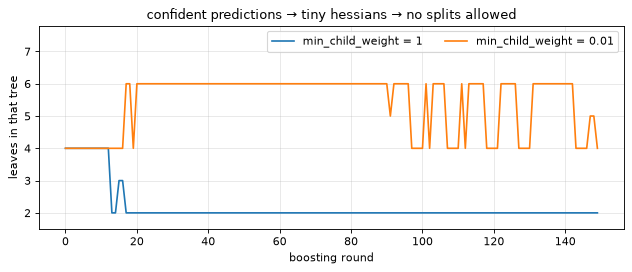

In [11]:
# min_child_weight: a confident model has tiny hessians, so a node needs MANY rows to reach H >= min_child_weight
for p in [0.5, 0.9, 0.99, 0.999]:
    print(f"p = {p:5}: h = p(1-p) = {p * (1 - p):.4f} -> rows needed for H >= 1: {int(np.ceil(1 / (p * (1 - p))))}")

rng = np.random.default_rng(0)
x_sep = rng.normal(size=(2000, 2))
y_sep = ((x_sep[:, 0] > 0) ^ (x_sep[:, 1] > 0.5)).astype(int)          # separable (a tilted XOR pattern)
fig, ax = plt.subplots(figsize=(8, 3.5))
for mcw in [1, 0.01]:                                                    # <- try changing this
    clf = xgb.XGBClassifier(n_estimators=150, max_depth=3, learning_rate=0.5, min_child_weight=mcw,
                            tree_method="exact", base_score=0.5).fit(x_sep, y_sep)
    n_leaves_per_tree = [len(leaves_of(tree_json(clf, i))) for i in range(150)]
    ax.plot(n_leaves_per_tree, label=f"min_child_weight = {mcw}")
    p_fit = clf.predict_proba(x_sep)[:, 1]
    print(f"min_child_weight={mcw}: leaves in trees 1, 20, 150 = {n_leaves_per_tree[0]}, {n_leaves_per_tree[19]}, {n_leaves_per_tree[-1]};"
          f"  total hessian of all 2000 rows at the end = {np.sum(p_fit * (1 - p_fit)):.2f}")
ax.set(xlabel="boosting round", ylabel="leaves in that tree", title="confident predictions → tiny hessians → no splits allowed",
       ylim=(1.5, 7.8))
ax.legend(loc="upper right", ncol=2); plt.tight_layout(); plt.show()

> **How to read this**
> * With p = 0.5 everywhere, g = 0.5 − y = ±0.5 and h = 0.25. The best split is `x < 3.5` (gain 0.514) and its
>   leaves are −G/(H+λ) = −1.5/1.75 = −0.857 (left) and +0.5/1.75 = +0.286 (right) — xgboost prints the same numbers.
> * A row the model is already sure about (p = 0.99) has h ≈ 0.0099: it counts as about 1/100 of a "row".
>   `min_child_weight = 1` then means "each child needs about 102 such rows".
> * The plot: with the default `min_child_weight = 1` the trees shrink from 4 leaves to 2 once the model is
>   confident — the total hessian of all 2 000 rows has fallen to a few units, so most children would be "too
>   light". Boosting quietly stops refining. With 0.01 the trees keep 4–6 leaves (see the plot) and push the
>   probabilities ever closer to 0 and 1 (total hessian 0.08).

## Lab 5 · XGBoost vs classic gradient boosting: same leaf formula, different split rule

**Goal:** README §6.5. scikit-learn's `GradientBoostingClassifier` fits each tree to the **negative gradients**
(first order) by least squares and then sets each leaf with one Newton step Σ(y − p)/Σp(1 − p). XGBoost uses the
hessians already when **choosing** splits. With λ = 0, round 1 (where every h is equal) must agree; later rounds
need not.

In [12]:
rng = np.random.default_rng(0)
X5 = rng.normal(size=(1000, 2))
y5 = (rng.random(1000) < 1 / (1 + np.exp(-(2 * X5[:, 0] - X5[:, 1] ** 2 + 1)))).astype(int)
for rounds in [1, 30]:
    sk = GradientBoostingClassifier(n_estimators=rounds, max_depth=2, learning_rate=0.3, random_state=0).fit(X5, y5)
    xg = xgb.XGBClassifier(n_estimators=rounds, max_depth=2, learning_rate=0.3, reg_lambda=0, min_child_weight=0,
                           tree_method="exact", base_score=float(y5.mean())).fit(X5, y5)
    a, b = sk.predict_proba(X5)[:, 1], xg.predict_proba(X5)[:, 1]
    print(f"{rounds:2d} rounds: max |p_sklearn − p_xgboost| = {np.abs(a - b).max():.2e};  "
          f"train log-loss sklearn {log_loss(y5, a):.4f}, xgboost {log_loss(y5, b):.4f}")

 1 rounds: max |p_sklearn − p_xgboost| = 4.92e-08;  train log-loss sklearn 0.6036, xgboost 0.6036
30 rounds: max |p_sklearn − p_xgboost| = 4.55e-01;  train log-loss sklearn 0.3832, xgboost 0.3819


> **How to read this**
> * After 1 round the two libraries agree to ~1e-7: same starting point (log-odds of the mean), same split
>   (all hessians equal, so both split rules rank splits the same way), same Newton leaf value.
> * After 30 rounds individual probabilities differ by up to ~0.46 because the trees differ: xgboost's split
>   score weights each row by its hessian p(1 − p), sklearn's does not. The overall fit is similar (log-loss
>   0.383 vs 0.382). So "second order" is mainly about *which splits you pick* and *any twice-differentiable loss*,
>   not about speed.

## Lab 6 · Learning rate η × number of trees

**Goal:** README §6.2. A smaller η takes smaller steps, so it needs more trees, but usually reaches a lower
validation error. We train on 4 500 rows and watch the error on 1 500 **validation** rows (the test set is not used).

 η      best validation RMSE   at tree   after 1500 trees


  1.0           1.790            14             2.088


  0.3           1.579            95             1.686


  0.1           1.520           249             1.572


 0.03           1.514          1268             1.518


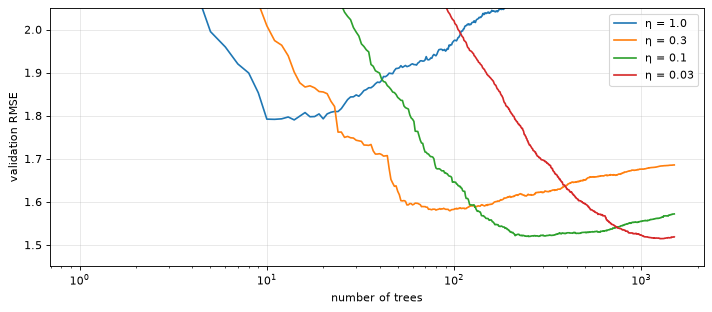

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
print(" η      best validation RMSE   at tree   after 1500 trees")
for eta_k in [1.0, 0.3, 0.1, 0.03]:                               # <- try changing this
    m = xgb.XGBRegressor(n_estimators=1500, learning_rate=eta_k, max_depth=4, tree_method="hist",
                         base_score=float(yg_fit.mean()), eval_metric="rmse")
    m.fit(Xg_fit, yg_fit, eval_set=[(Xg_val, yg_val)], verbose=False)
    curve = np.array(m.evals_result()["validation_0"]["rmse"])
    ax.plot(np.arange(1, 1501), curve, label=f"η = {eta_k}")
    print(f"{eta_k:5}  {curve.min():14.3f}  {curve.argmin() + 1:12d}  {curve[-1]:16.3f}")
ax.set(xscale="log", ylim=(1.45, 2.05), xlabel="number of trees", ylabel="validation RMSE")
ax.legend(); plt.tight_layout(); plt.show()

> **How to read this**
> * η = 1 drops fastest, bottoms out early and then gets **worse**: 1.790 at tree 14, **2.088** after 1 500 trees
>   (last column). Each tree makes a full Newton step and the later trees fit noise. The smaller η values rise
>   less (0.3: 1.579 → 1.686; 0.1: 1.520 → 1.572), and at η = 0.03 the curve has barely turned (1.514 → 1.518).
> * Smaller η → the minimum moves to the right (more trees needed) and gets lower. Between 0.1 and 0.03 the
>   gain is small but the cost (trees, time) is ~3× larger. That is the usual trade-off: pick a small η you can
>   afford, then choose the number of trees with early stopping (next lab).

## Lab 7 · Early stopping on a validation set (test set touched once)

**Goal:** README §6.3. Give xgboost a validation set and `early_stopping_rounds`: it stops when the validation
error has not improved for that many rounds, remembers the best round, and `predict` uses the trees up to it.

trees built      : 604
best_iteration   : 553  (0-based) -> predict() uses 554 trees
best val RMSE    : 1.5279
TEST RMSE (once) : 1.4557


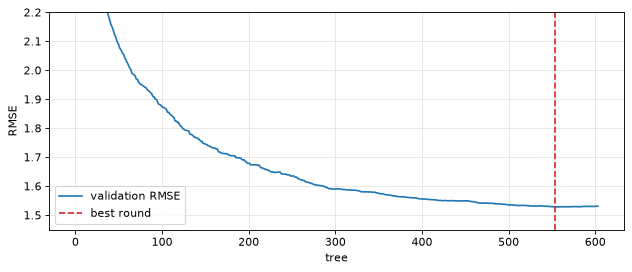

In [14]:
es = xgb.XGBRegressor(n_estimators=5000, learning_rate=0.05, max_depth=4, tree_method="hist",
                      base_score=float(yg_fit.mean()), eval_metric="rmse", early_stopping_rounds=50)   # <- try changing this
es.fit(Xg_fit, yg_fit, eval_set=[(Xg_val, yg_val)], verbose=False)
curve = es.evals_result()["validation_0"]["rmse"]
print("trees built      :", es.get_booster().num_boosted_rounds())
print("best_iteration   :", es.best_iteration, " (0-based) -> predict() uses", es.best_iteration + 1, "trees")
print(f"best val RMSE    : {es.best_score:.4f}")
print(f"TEST RMSE (once) : {rmse(yg_te, es.predict(Xg_te)):.4f}")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(curve, label="validation RMSE"); ax.axvline(es.best_iteration, color="tab:red", ls="--", label="best round")
ax.set(xlabel="tree", ylabel="RMSE", ylim=(1.45, 2.2)); ax.legend(); plt.tight_layout(); plt.show()

> **How to read this**
> * Training stopped by itself: the printed number of trees built is the best round + 1 + 50 patience rounds.
> * The test RMSE is computed **once**, after every choice was made on the validation set. If we had stopped at
>   the round that was best on the *test* set, the test number would be optimistic (leakage).
> * In xgboost ≥ 2, `early_stopping_rounds` belongs in the **constructor**; passing it to `fit` is the old API.

### Lab 7 (continued) · Noisy labels: too many rounds make it worse, early stopping fixes it

**Goal:** README §6.3 and the root README's "boosting can over-fit noise". Lab 6's data has noise only in
the target values, so its curves rise gently. Here the **labels** are noisy: `flip_y=0.3` re-draws 30 % of the
labels at random, so about 15 % end up wrong. Same setup as the gradient-boosting module's Lab 16 (η = 0.3,
depth 4, up to 500 rounds), so the two libraries can be compared. The test set is touched once, at the end.

validation log-loss: best 0.474 at 11 trees, after 500 trees 0.744; training log-loss after 500 trees 0.013
500 rounds                   test log-loss 0.865, test accuracy 0.765
early stopping (11 trees)    test log-loss 0.533, test accuracy 0.760


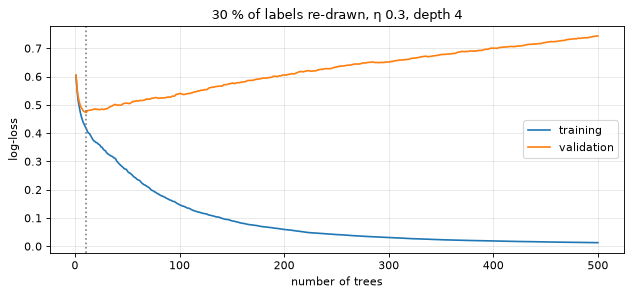

In [15]:
Xn, yn = make_classification(n_samples=3000, n_features=10, n_informative=5, flip_y=0.3, random_state=0)
Xn_tv, Xn_te, yn_tv, yn_te = train_test_split(Xn, yn, test_size=0.25, random_state=0)
Xn_tr, Xn_va, yn_tr, yn_va = train_test_split(Xn_tv, yn_tv, test_size=0.25, random_state=0)
noisy_params = dict(learning_rate=0.3, max_depth=4, tree_method="hist", eval_metric="logloss")   # <- try changing this

noisy = xgb.XGBClassifier(n_estimators=500, **noisy_params)
noisy.fit(Xn_tr, yn_tr, eval_set=[(Xn_tr, yn_tr), (Xn_va, yn_va)], verbose=False)
tr_ll = np.array(noisy.evals_result()["validation_0"]["logloss"])
va_ll = np.array(noisy.evals_result()["validation_1"]["logloss"])
best = int(va_ll.argmin()) + 1
print(f"validation log-loss: best {va_ll.min():.3f} at {best} trees, after 500 trees {va_ll[-1]:.3f}; "
      f"training log-loss after 500 trees {tr_ll[-1]:.3f}")

stopped = xgb.XGBClassifier(n_estimators=500, early_stopping_rounds=10, **noisy_params)
stopped.fit(Xn_tr, yn_tr, eval_set=[(Xn_va, yn_va)], verbose=False)
for name, model in [("500 rounds", noisy), (f"early stopping ({stopped.best_iteration + 1} trees)", stopped)]:
    print(f"{name:<28} test log-loss {log_loss(yn_te, model.predict_proba(Xn_te)):.3f}, "
          f"test accuracy {accuracy_score(yn_te, model.predict(Xn_te)):.3f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(np.arange(1, 501), tr_ll, label="training"); ax.plot(np.arange(1, 501), va_ll, label="validation")
ax.axvline(best, color="gray", ls=":")
ax.set(xlabel="number of trees", ylabel="log-loss", title="30 % of labels re-drawn, η 0.3, depth 4")
ax.legend(); plt.tight_layout(); plt.show()

> **How to read this**
> * The validation log-loss is best after only **11 trees** (0.474) and then **climbs** to 0.744 after 500, while
>   the training log-loss heads to 0 (0.013): the extra rounds memorise the re-drawn labels.
> * Early stopping (patience 10 rounds, on the validation set) keeps **11 trees**: test log-loss **0.533** instead
>   of **0.865**. Accuracy hardly moves (0.760 vs 0.765) — the damage is in the **probabilities**, which become
>   over-confident.
> * Same shape as scikit-learn's gradient boosting on the same data (gradient-boosting module, Lab 16: best at
>   9 trees, 0.491 → 0.909). Smaller η, shallower trees, `subsample < 1` and larger `reg_lambda` also slow the rise.

## Lab 8 · exact vs approx vs hist: how split finding scales

**Goal:** README §4.8. `exact` sorts every feature and tries every gap; `approx` re-bins features with a weighted
quantile sketch at every tree; `hist` bins once (default `max_bin = 256`) and then works on bin sums. How do time
and accuracy change as the data grows?

In [16]:
X_big, y_big = make_good_fit(seed=1, n=74000, save=False)
X_hold, y_hold = X_big[-10000:], y_big[-10000:]                       # fixed evaluation rows
settings = [("exact", {}), ("approx", {}), ("hist", {}), ("hist", {"max_bin": 16})]
results = {}
print("     n    " + "   ".join(f"{tm + (' max_bin=16' if kw else ''):>18s}" for tm, kw in settings))
for n in [2000, 8000, 32000, 64000]:                                  # <- try changing this
    line = f"{n:6d}  "
    for tm, kw in settings:
        m = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, tree_method=tm,
                             base_score=float(y_big[:n].mean()), **kw)
        t0 = time.perf_counter(); m.fit(X_big[:n], y_big[:n]); dt = time.perf_counter() - t0
        results[(n, tm, bool(kw))] = (dt, rmse(y_hold, m.predict(X_hold)))
        line += f"  {dt:6.2f}s RMSE {results[(n, tm, bool(kw))][1]:.3f}"
    print(line)

     n                 exact               approx                 hist      hist max_bin=16


  2000      0.09s RMSE 1.739    0.09s RMSE 1.733    0.09s RMSE 1.733    0.05s RMSE 1.727


  8000      0.26s RMSE 1.538    0.14s RMSE 1.526    0.08s RMSE 1.526    0.06s RMSE 1.559


 32000      0.61s RMSE 1.445    0.15s RMSE 1.444    0.10s RMSE 1.444    0.07s RMSE 1.483


 64000      1.08s RMSE 1.410    0.28s RMSE 1.412    0.17s RMSE 1.412    0.13s RMSE 1.462


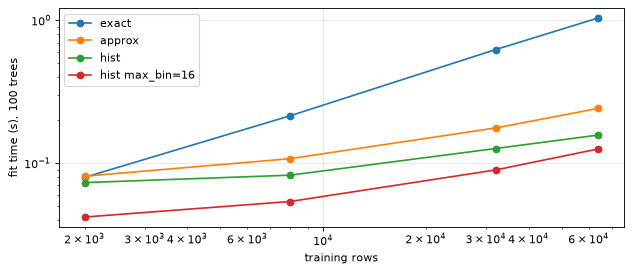

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ns = [2000, 8000, 32000, 64000]
for tm, kw in settings:
    ax.plot(ns, [results[(n, tm, bool(kw))][0] for n in ns], "o-", label=tm + (" max_bin=16" if kw else ""))
ax.set(xscale="log", yscale="log", xlabel="training rows", ylabel="fit time (s), 100 trees")
ax.legend(); plt.tight_layout(); plt.show()

> **How to read this**
> * Accuracy: `exact`, `approx` and `hist` (256 bins) are within 0.012 RMSE of each other at every size — 256
>   bins lose almost nothing. With only 16 bins the error is visibly higher once there is enough data to use
>   finer thresholds (1.462 vs 1.412 at 64 000 rows).
> * Time: `exact` grows fastest with n; at 64 000 rows `hist` is several times faster (see the last line of the
>   table and the plot). `approx` sits in between (it rebuilds its bins for every tree). The gap widens with more
>   rows and features. (Timings vary a little from run to run; the ranking does not.)
> * On small data all methods are fast and `exact` is fine; on large data `hist` (the default) is the practical choice.

---
# Part B — Why XGBoost is useful

## Lab 9 · Missing values: built-in default direction vs imputation

**Goal:** README §4.9 and §7. On the good-fit data, compare (same trees: 300 × depth 4, η = 0.1):
xgboost on the raw data with NaN, xgboost after **mean imputation**, xgboost after mean imputation **plus
missing-indicator columns**, scikit-learn's `GradientBoostingRegressor` (which refuses NaN, so it must be imputed),
and `HistGradientBoostingRegressor` (which also handles NaN natively). Imputers sit inside a `Pipeline`, so they
learn the column means from the training rows only.

In [18]:
common = dict(n_estimators=300, learning_rate=0.1, max_depth=4)
candidates = {
    "xgboost, NaN as is": xgb.XGBRegressor(**common, base_score=float(yg_tr.mean())),
    "xgboost, mean-imputed": make_pipeline(SimpleImputer(strategy="mean"), xgb.XGBRegressor(**common, base_score=float(yg_tr.mean()))),
    "xgboost, mean + indicator": make_pipeline(SimpleImputer(strategy="mean", add_indicator=True), xgb.XGBRegressor(**common, base_score=float(yg_tr.mean()))),
    "sklearn GBM, mean-imputed": make_pipeline(SimpleImputer(strategy="mean"), GradientBoostingRegressor(**common, random_state=0)),
    "sklearn HistGB, NaN as is": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, max_depth=4, early_stopping=False, random_state=0),
}
lab9 = {}
print(f"{'model':28s} {'test RMSE':>9s} {'test R²':>8s} {'fit time':>9s}")
for name, model in candidates.items():
    t0 = time.perf_counter(); model.fit(Xg_tr, yg_tr); dt = time.perf_counter() - t0
    pred = model.predict(Xg_te)
    lab9[name] = (rmse(yg_te, pred), r2_score(yg_te, pred), dt)
    print(f"{name:28s} {lab9[name][0]:9.3f} {lab9[name][1]:8.3f} {dt:8.2f}s")

model                        test RMSE  test R²  fit time


xgboost, NaN as is               1.412    0.835     0.12s


xgboost, mean-imputed            1.564    0.797     0.10s


xgboost, mean + indicator        1.424    0.832     0.12s


sklearn GBM, mean-imputed        1.566    0.797     2.55s


sklearn HistGB, NaN as is        1.428    0.831     0.59s


**Where does a missing value go?** Look at the first split on a column with blanks: the dump says which child
receives the missing rows (`missing` = the node id of that child), learned by trying both sides.

In [19]:
def first_split_on(node, feature):
    if "leaf" in node:
        return None
    if node["split"] == feature:
        return node
    for child in node["children"]:
        found = first_split_on(child, feature)
        if found:
            return found


print("largest observed x3 in the training rows:", np.nanmax(Xg_tr[:, 2]))
for i in range(3):
    s = first_split_on(tree_json(candidates["xgboost, NaN as is"], i), "f2")
    if s:
        side = "left (yes)" if s["missing"] == s["yes"] else "right (no)"
        print(f"tree {i}: split x3 < {s['split_condition']:.4f}  -> missing rows go {side}")

largest observed x3 in the training rows: 2.778
tree 0: split x3 < 5.5560  -> missing rows go right (no)
tree 1: split x3 < 1.5010  -> missing rows go right (no)
tree 2: split x3 < 5.5560  -> missing rows go right (no)


**"Zeros are missing" is only true for sparse input.** In a normal (dense) NumPy array, 0 is a value and only NaN
is missing. In a `scipy.sparse` matrix, entries that are not stored (the zeros) are treated as missing.

In [20]:
x_z = np.array([[0.0], [0.0], [0.0], [1.0], [2.0], [3.0]])
y_z = np.array([10, 10, 10, 0, 0, 1], dtype=float)
for name, data in [("dense array", x_z), ("scipy CSR (zeros not stored)", scipy.sparse.csr_matrix(x_z))]:
    m = xgb.XGBRegressor(n_estimators=1, max_depth=1, learning_rate=1, tree_method="exact", base_score=float(y_z.mean())).fit(data, y_z)
    t = tree_json(m)
    print(f"{name:30s}: split x < {t['split_condition']}, missing -> node {t['missing']} (yes = node {t['yes']})")

dense array                   : split x < 0.5, missing -> node 1 (yes = node 1)
scipy CSR (zeros not stored)  : split x < 6.00000095, missing -> node 2 (yes = node 1)


> **How to read this**
> * Native NaN handling wins clearly: xgboost on the raw data and HistGB (also native) are close to each other
>   and well ahead of mean imputation (xgboost or sklearn GBM). Imputing with the mean puts a blank row in the
>   middle of the real values, so the model needs extra splits to find those rows again, and the information
>   "this was blank" gets mixed up with "this value was average".
> * Adding indicator columns gives the information back and closes most of the gap — a good fix for models
>   without native handling.
> * Each split on `x3` has a learned default direction: the dump shows which side the blanks go. Trees 0 and 2
>   even split at x3 < 5.556 — larger than every observed x3 — so *all* observed values go left and only the
>   blank rows go right: the split literally asks "is x3 missing?".
> * Dense vs sparse: with a dense array xgboost splits *between* 0 and 1 (`x < 0.5`), treating 0 as a number.
>   With a CSR matrix the zeros are "not stored" = missing, so the split is between the stored values and the
>   zeros go to the learned default side. Same numbers, different meaning — know which input you pass.

## Lab 10 · Row and column subsampling

**Goal:** README §6.2. `subsample` trains each tree on a random share of the rows, `colsample_bytree` on a random
share of the columns. Both make the trees less alike (and faster). Does it help here? Scored on the validation set.

In [21]:
print("subsample  colsample_bytree   val RMSE   fit time")
for sub in [1.0, 0.8, 0.5]:                                      # <- try changing this
    for col in [1.0, 0.8, 0.5]:
        m = xgb.XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=4, subsample=sub, colsample_bytree=col,
                             random_state=0, base_score=float(yg_fit.mean()))
        t0 = time.perf_counter(); m.fit(Xg_fit, yg_fit); dt = time.perf_counter() - t0
        print(f"{sub:9.1f} {col:17.1f} {rmse(yg_val, m.predict(Xg_val)):10.3f} {dt:9.2f}s")

subsample  colsample_bytree   val RMSE   fit time
      1.0               1.0      1.522      0.12s


      1.0               0.8      1.533      0.11s
      1.0               0.5      1.537      0.10s


      0.8               1.0      1.496      0.11s
      0.8               0.8      1.493      0.10s
      0.8               0.5      1.507      0.09s


      0.5               1.0      1.506      0.11s
      0.5               0.8      1.533      0.10s


      0.5               0.5      1.525      0.10s


> **How to read this**
> * The differences are modest (hundredths of RMSE). Mild subsampling (0.8) is often a small win or neutral;
>   halving the columns hurts a little here because only 8 columns exist and each tree then misses some
>   important ones.
> * Subsampling is a variance-reduction tool (like bagging inside boosting). It matters more for big, noisy
>   data and deep trees; treat it as a knob to validate, not a guaranteed improvement.

## Lab 11 · Monotone constraints

**Goal:** README §6.2. If you *know* the prediction should only go up with a feature (price with size, risk with
age), `monotone_constraints` forces every tree to respect that.

none : downward steps on the grid = 78
(1)  : downward steps on the grid = 0


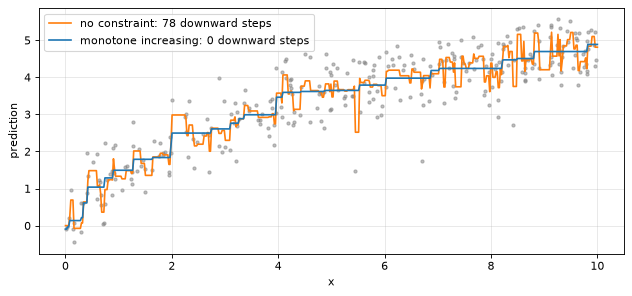

In [22]:
rng = np.random.default_rng(0)
x_m = rng.uniform(0, 10, (300, 1))
y_m = np.log1p(x_m[:, 0]) * 2 + rng.normal(scale=0.6, size=300)        # increasing trend + noise
grid_m = np.linspace(0, 10, 500).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(x_m, y_m, s=8, color="gray", alpha=0.5)
for cons, c in [(None, "tab:orange"), ("(1)", "tab:blue")]:
    kw = {} if cons is None else {"monotone_constraints": cons}
    m = xgb.XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=4, base_score=float(y_m.mean()), **kw).fit(x_m, y_m)
    curve = m.predict(grid_m)
    drops = int((np.diff(curve) < -1e-6).sum())
    ax.plot(grid_m, curve, color=c, label=f"{'no constraint' if cons is None else 'monotone increasing'}: {drops} downward steps")
    print(f"{'none' if cons is None else cons:5s}: downward steps on the grid = {drops}")
ax.set(xlabel="x", ylabel="prediction"); ax.legend(); plt.tight_layout(); plt.show()

> **How to read this**
> * Without a constraint the curve wiggles down in many places — it follows noise.
> * With `monotone_constraints="(1)"` there are 0 downward steps: every split's leaves are forced to respect the
>   order (and the leaf values are clipped so later splits cannot break it). Domain knowledge acts as a regulariser.

---
# Part C — Where XGBoost fails

## Lab 12 · p ≫ n with a sparse linear signal (the bad-fit dataset)

**Goal:** README §8.1. 105 training rows, 400 features, y = a straight-line function of 10 of them. Compare
xgboost (number of trees by early stopping on a validation split of the training rows) with Lasso and Ridge
(penalty chosen by cross-validation on the training rows). Test set used once.

In [23]:
Xb_fit, Xb_val, yb_fit, yb_val = train_test_split(Xb_tr, yb_tr, test_size=0.25, random_state=0)
xgb_bad = xgb.XGBRegressor(n_estimators=2000, learning_rate=0.05, max_depth=3, base_score=float(yb_fit.mean()),
                           eval_metric="rmse", early_stopping_rounds=50)
xgb_bad.fit(Xb_fit, yb_fit, eval_set=[(Xb_val, yb_val)], verbose=False)
xgb_true10 = xgb.XGBRegressor(n_estimators=2000, learning_rate=0.05, max_depth=3, base_score=float(yb_fit.mean()),
                              eval_metric="rmse", early_stopping_rounds=50)
xgb_true10.fit(Xb_fit[:, :10], yb_fit, eval_set=[(Xb_val[:, :10], yb_val)], verbose=False)
lasso = LassoCV(cv=5, random_state=0, max_iter=20000).fit(Xb_tr, yb_tr)
ridge = RidgeCV(alphas=np.logspace(-2, 4, 30)).fit(Xb_tr, yb_tr)
print(f"{'model':40s} {'test RMSE':>9s} {'test R²':>8s}")
for name, pred in [("xgboost, all 400 features", xgb_bad.predict(Xb_te)),
                   ("xgboost, only the 10 true features", xgb_true10.predict(Xb_te[:, :10])),
                   ("RidgeCV (L2 linear)", ridge.predict(Xb_te)),
                   ("LassoCV (L1 linear)", lasso.predict(Xb_te))]:
    print(f"{name:40s} {rmse(yb_te, pred):9.3f} {r2_score(yb_te, pred):8.3f}")
print("std of y in the test set:", round(float(yb_te.std()), 3))
print("Lasso: non-zero coefficients", int(np.count_nonzero(lasso.coef_)), "; of the true 10 it kept",
      int(np.count_nonzero(lasso.coef_[:10])))

model                                    test RMSE  test R²
xgboost, all 400 features                    4.433    0.187
xgboost, only the 10 true features           3.320    0.544
RidgeCV (L2 linear)                          4.501    0.162
LassoCV (L1 linear)                          1.341    0.926
std of y in the test set: 4.916
Lasso: non-zero coefficients 73 ; of the true 10 it kept 10


> **How to read this**
> * xgboost on all 400 features barely beats predicting the mean (R² close to 0). Lasso explains most of the
>   variance (R² ≈ 0.9): its shape — a weighted sum with most weights exactly 0 — **is** the true model.
> * Even when we hand xgboost only the 10 true features it stays far behind Lasso: with ~80 rows, trees can only
>   approximate a 10-dimensional tilted plane by a few coarse steps.
> * Ridge is no better than xgboost here (R² 0.16): right shape (linear), wrong kind of regularisation — it
>   spreads small weights over all 400 features instead of picking 10. Lasso kept all 10 true features (plus
>   63 small extras).

## Lab 13 · Extrapolation: trees go flat outside the training range

**Goal:** README §8.2. Train on x in [0, 10] with a straight-line trend, then ask for x up to 15.

prediction at x = 10, 12.5, 15: [29.911 29.911 29.911]   truth: [30, 37.5, 45]


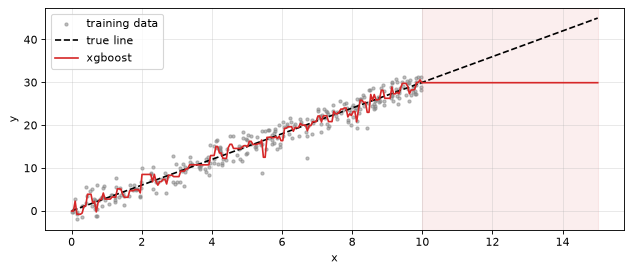

In [24]:
rng = np.random.default_rng(0)
x_e = rng.uniform(0, 10, (300, 1))
y_e = 3 * x_e[:, 0] + rng.normal(scale=2, size=300)
grid_e = np.linspace(0, 15, 300).reshape(-1, 1)
m_e = xgb.XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=3, base_score=float(y_e.mean())).fit(x_e, y_e)
pred_e = m_e.predict(grid_e)
print("prediction at x = 10, 12.5, 15:", m_e.predict(np.array([[10.0], [12.5], [15.0]])), "  truth:", [30, 37.5, 45])
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.scatter(x_e, y_e, s=8, color="gray", alpha=0.5, label="training data")
ax.plot(grid_e, 3 * grid_e, "k--", label="true line"); ax.plot(grid_e, pred_e, color="tab:red", label="xgboost")
ax.axvspan(10, 15, color="tab:red", alpha=0.08); ax.set(xlabel="x", ylabel="y"); ax.legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * Inside [0, 10] the steps follow the line. Beyond 10 the prediction is **flat**: every tree sends x = 12.5 and
>   x = 15 to the same right-most leaf as x = 10, so all three predictions are identical.
> * A sum of trees is piecewise constant; it cannot continue a trend. Use a linear model (or model the trend
>   separately and boost the residuals) when you must predict outside the training range.

## Lab 14 · Tiny noisy data and over-tuning

**Goal:** README §8.3. With 60 rows, pick the best of 40 random xgboost settings by 5-fold cross-validation. The
winner's CV score is **optimistic** (it was the luckiest of 40); a large fresh test set shows the truth. A plain
ridge regression is the baseline.

In [25]:
def make_tiny(seed, n):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, 5))
    return X, X[:, 0] + 0.5 * X[:, 1] + rng.normal(scale=1.0, size=n)


X_tiny, y_tiny = make_tiny(0, 60)
X_fresh, y_fresh = make_tiny(1, 5000)
cv = KFold(5, shuffle=True, random_state=0)
rng = np.random.default_rng(0)
trials = []
for _ in range(40):                                                 # <- try changing this
    params = dict(n_estimators=int(rng.integers(20, 400)), learning_rate=float(10 ** rng.uniform(-2, -0.3)),
                  max_depth=int(rng.integers(1, 7)), min_child_weight=float(10 ** rng.uniform(-1, 1)),
                  subsample=float(rng.uniform(0.5, 1)), colsample_bytree=float(rng.uniform(0.5, 1)),
                  reg_lambda=float(10 ** rng.uniform(-2, 2)), gamma=float(10 ** rng.uniform(-3, 0.5)))
    model = xgb.XGBRegressor(**params, base_score=float(y_tiny.mean()), random_state=0)
    trials.append((cross_val_score(model, X_tiny, y_tiny, cv=cv, scoring="r2").mean(), params))
best_cv, best_params = max(trials, key=lambda t: t[0])
best = xgb.XGBRegressor(**best_params, base_score=float(y_tiny.mean()), random_state=0).fit(X_tiny, y_tiny)
ridge_tiny = RidgeCV(alphas=np.logspace(-2, 3, 30)).fit(X_tiny, y_tiny)
print(f"CV R² of the 40 settings: from {min(t[0] for t in trials):.3f} to {best_cv:.3f}")
print(f"best setting: CV R² = {best_cv:.3f}  ->  fresh-data R² = {r2_score(y_fresh, best.predict(X_fresh)):.3f}")
print(f"RidgeCV     : CV R² = {cross_val_score(RidgeCV(alphas=np.logspace(-2, 3, 30)), X_tiny, y_tiny, cv=cv).mean():.3f}"
      f"  ->  fresh-data R² = {r2_score(y_fresh, ridge_tiny.predict(X_fresh)):.3f}")
print("best possible R² (true function):", round(r2_score(y_fresh, X_fresh[:, 0] + 0.5 * X_fresh[:, 1]), 3))

CV R² of the 40 settings: from 0.106 to 0.507
best setting: CV R² = 0.507  ->  fresh-data R² = 0.350
RidgeCV     : CV R² = 0.445  ->  fresh-data R² = 0.539
best possible R² (true function): 0.556


> **How to read this**
> * The 40 settings' CV scores spread widely; the winner looks best partly by luck. On fresh data it scores
>   **lower** than its CV number — that gap is the optimism of picking the maximum of many noisy estimates.
> * Ridge, with one knob, is better on fresh data and closer to the best possible R². With tiny noisy data a
>   flexible model with many knobs has more ways to fool you than to help you.

## Lab 15 · Many categories: one-hot vs native categorical splits

**Goal:** README §8.4. One categorical feature with 300 levels (each with its own effect) plus one numeric
feature. One-hot encoding turns it into 300 sparse 0/1 columns, so each split can only peel off **one** level.
xgboost's native categorical support (`enable_categorical=True`, `feature_types`, `hist` method) can put
**many** levels on each side of one split.

In [26]:
rng = np.random.default_rng(0)
n_c, K = 4000, 300
cat = rng.integers(0, K, n_c)
effect = rng.normal(scale=2, size=K)
x2_c = rng.normal(size=n_c)
y_cat = effect[cat] + x2_c + rng.normal(scale=0.5, size=n_c)
tr = np.arange(n_c) < 3000
one_hot = np.column_stack([np.eye(K)[cat], x2_c])
codes = np.column_stack([cat.astype(float), x2_c])
base_c = dict(n_estimators=300, learning_rate=0.1, max_depth=4, tree_method="hist", base_score=float(y_cat[tr].mean()))
print(f"{'encoding':32s} {'test RMSE':>9s} {'fit time':>9s}")
for name, Xc, extra in [("one-hot (301 columns)", one_hot, {}),
                        ("integer codes as numbers", codes, {}),
                        ("native categorical", codes, dict(enable_categorical=True, feature_types=["c", "q"]))]:
    t0 = time.perf_counter(); m = xgb.XGBRegressor(**base_c, **extra).fit(Xc[tr], y_cat[tr]); dt = time.perf_counter() - t0
    print(f"{name:32s} {rmse(y_cat[~tr], m.predict(Xc[~tr])):9.3f} {dt:8.2f}s")
print("noise level (best possible RMSE): 0.5")

encoding                         test RMSE  fit time


one-hot (301 columns)                1.195     0.33s
integer codes as numbers             1.316     0.19s


native categorical                   0.606     0.13s
noise level (best possible RMSE): 0.5


> **How to read this**
> * One-hot and "codes as numbers" both leave a large error: each one-hot split isolates one of 300 levels, and
>   numeric codes impose a meaningless order. 300 trees × depth 4 cannot sort out 300 levels that way.
> * Native categorical splits partition the levels into two groups at once (ordered by their gradient
>   statistics) and get much closer to the noise floor of 0.5.
> * Native support needs `tree_method="hist"` (or `approx`) and must be told which columns are categories.

## Lab 16 · The tuning burden

**Goal:** README §8.5. xgboost has dozens of parameters; at least eight matter regularly. A random search on the
good-fit data shows how much the result depends on them (scored on the validation set).

parameters in XGBRegressor().get_params(): 40


validation RMSE of 30 random settings: best 1.516, median 1.772, worst 2.724
defaults (100 trees, η = 0.3, depth 6): 1.672


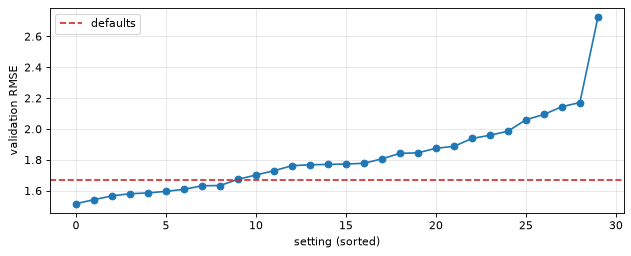

In [27]:
print("parameters in XGBRegressor().get_params():", len(xgb.XGBRegressor().get_params()))
rng = np.random.default_rng(1)
val_scores = []
for _ in range(30):                                                 # <- try changing this
    params = dict(learning_rate=float(10 ** rng.uniform(-2, 0)), max_depth=int(rng.integers(1, 11)),
                  min_child_weight=float(10 ** rng.uniform(-1, 2)), subsample=float(rng.uniform(0.4, 1)),
                  colsample_bytree=float(rng.uniform(0.3, 1)), reg_lambda=float(10 ** rng.uniform(-2, 2)),
                  reg_alpha=float(10 ** rng.uniform(-3, 1)), gamma=float(10 ** rng.uniform(-3, 1.5)))
    m = xgb.XGBRegressor(n_estimators=300, **params, base_score=float(yg_fit.mean()), random_state=0).fit(Xg_fit, yg_fit)
    val_scores.append(rmse(yg_val, m.predict(Xg_val)))
default_score = rmse(yg_val, xgb.XGBRegressor(base_score=float(yg_fit.mean())).fit(Xg_fit, yg_fit).predict(Xg_val))
val_scores = np.sort(val_scores)
print(f"validation RMSE of 30 random settings: best {val_scores[0]:.3f}, median {np.median(val_scores):.3f}, worst {val_scores[-1]:.3f}")
print(f"defaults (100 trees, η = 0.3, depth 6): {default_score:.3f}")
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.plot(val_scores, "o-"); ax.axhline(default_score, color="tab:red", ls="--", label="defaults")
ax.set(xlabel="setting (sorted)", ylabel="validation RMSE"); ax.legend(); plt.tight_layout(); plt.show()

> **How to read this**
> * The same algorithm on the same data ranges from good to poor depending only on hyper-parameters; random
>   settings are often *worse* than the defaults.
> * The defaults are a reasonable start, but getting the best out of xgboost needs a validation scheme and a
>   search budget (time, compute, and care not to over-tune — Lab 14). A random forest is far less sensitive.

---
# Summary — what each lab showed

| Lab | Claim from the README | Verdict |
|---|---|---|
| 1 | Hand example: gains 36 / 3.75, leaves −3, 1, 4.5, predictions 5.1 / 6.3 / 7.35; xgboost reports gain without the ½ | ✔ same numbers |
| 2 | Histogram example: split after bin 1 has gain 0.434, after bin 2 0.287; quantile bins land near the exact optimum | ✔ |
| 3 | λ shrinks every leaf weight and lowers gains; γ prunes weak splits; α zeroes small leaves | ✔ |
| 4 | Logistic: g = p − y, h = p(1 − p); min_child_weight = minimum hessian ("confidence-weighted count") | ✔ |
| 5 | Same Newton leaf as sklearn's GBM, but splits chosen with hessians | ✔ round 1 identical, later rounds differ |
| 6 | Smaller η needs more trees and usually ends lower; η = 1 gets worse after its minimum | ✔ 1.790 → 2.088 |
| 7 | Early stopping picks the number of trees on validation data; with noisy labels extra rounds over-fit and early stopping fixes it | ✔ test log-loss 0.533 vs 0.865 |
| 8 | exact / approx / hist give similar accuracy; hist is much faster on large n | ✔ |
| 9 | Native missing-value handling beats mean imputation on informative blanks; 0 ≠ missing in dense input | ✔ |
| 10 | Subsampling is a modest, data-dependent regulariser | ✔ |
| 11 | Monotone constraints enforce known shape | ✔ 0 downward steps |
| 12 | ✘ p ≫ n with a sparse linear signal → Lasso wins by far | failure shown |
| 13 | ✘ Trees cannot extrapolate a trend | failure shown |
| 14 | ✘ Tiny noisy data: tuning many knobs gives optimistic CV and loses to ridge | failure shown |
| 15 | ✘ High-cardinality one-hot is inefficient; native categorical splits fix it | failure shown |
| 16 | ✘ Results depend strongly on many hyper-parameters | failure shown |